# Insight Hunters (ResNet50 Model Development)

## Purpose

This notebook develops and trains a ResNet50 transfer-learning model for binary tuberculosis classification using the prepared Shenzhen and Montgomery chest X-ray dataset.

The model follows the Insight Hunters common model experiment protocol to ensure a controlled comparison with VGG16, DenseNet121 and EfficientNet-B0.

### Dataset

- Total images: 800
- Training: 560
- Validation: 120
- Testing: 120

Classes:
  - 0 = TB Negative
  - 1 = TB Positive

Input size: 224 × 224 × 3

### Experimental Rules

- Random seed: 42
- Batch size: 32
- ImageNet pretrained weights
- Training-only data augmentation
- Stage 1 uses a frozen pretrained convolutional base
- Validation loss is used for early stopping and checkpointing
- The test set remains locked during model development
- Fine-tuning is performed only after Stage 1
- Final outputs follow the shared Insight Hunters output structure

### ResNet50 - Specific Decisions

| Item | Decision |
|---|---|
| Preprocessing | `resnet50.preprocess_input` (RGB → BGR, ImageNet channel-mean subtraction, no scaling) |
| Stage 2 unfrozen portion | The last residual stage, `conv5_block1` (only convolutional layers) |
| BatchNormalization | **Kept frozen in BOTH stages.** The base is always called with `training=False`, so BN layers run in inference mode and their moving statistics are not corrupted by a small training set. |
| Head, optimiser, LRs, epochs, patience | Identical to requirements of the model development guideline |


In [ ]:
# setting up environment - loading libraries needed for ResNet50 model training and checking GPU


#importing req. libraries
from pathlib import Path
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

#mounting drive
from google.colab import drive
drive.mount("/content/drive")

#reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

#GPU info
gpus = tf.config.list_physical_devices("GPU")

print("=" * 65)
print("ResNet50 - Environment Check")
print("=" * 65)

print(f"TensorFlow Version: {tf.__version__}")
print(f"Random Seed:        {SEED}")

if gpus:
  print("GPU detected:       YES")
  print(f"GPU device:         {gpus[0].name}")
else:
   print("GPU detected:       NO")

print("=" * 65)

Mounted at /content/drive
ResNet50 - Environment Check
TensorFlow Version: 2.20.0
Random Seed:        42
GPU detected:       YES
GPU device:         /physical_device:GPU:0


In [ ]:
#ResNet50 (Dataset path configuration)

#accessing project directories
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

DATA_SPLIT_ROOT = PROJECT_ROOT / "02_Data_Splits"
TRAIN_DIR = DATA_SPLIT_ROOT / "train"
VAL_DIR = DATA_SPLIT_ROOT / "val"

#expected class folders
EXPECTED_CLASSES = [
    "tb_negative",
    "tb_positive"
]

#expected image counts
EXPECTED_TRAIN_SIZE = 560
EXPECTED_VAL_SIZE = 120

#verifying directories
print("=" * 65)
print("ResNet50 - Dataset Path verification:")
print("=" * 65)

for dir_name, directory in [
    ("training", TRAIN_DIR),
    ("validation", VAL_DIR)
]:
    if not directory.exists():
      raise FileNotFoundError(
          f"{dir_name} directory not found:\n{directory}"
      )

    class_folders = sorted(
        folder.name
        for folder in directory.iterdir()
        if folder.is_dir()
    )

    if class_folders != EXPECTED_CLASSES:
      raise ValueError(
          f"{dir_name} class folders are incorrect. \n"
          f"Expected: {EXPECTED_CLASSES}\n"
          f"Found: {class_folders}"
      )

    print(f"✓ {dir_name} directory")
    print(f"  Classes: {class_folders}")

print()
print("TEST SET: NOT LOADED - LOCKED FOR FINAL EVALUATION")

print("=" * 65)
print("DATASET PATH VERIFICATION PASSED")


ResNet50 - Dataset Path verification:
✓ training directory
  Classes: ['tb_negative', 'tb_positive']
✓ validation directory
  Classes: ['tb_negative', 'tb_positive']

TEST SET: NOT LOADED - LOCKED FOR FINAL EVALUATION
DATASET PATH VERIFICATION PASSED


In [ ]:
#ResNet50 - loading and validating datasets

#shared config
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

#training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels = "inferred",
    label_mode = "binary",
    class_names = EXPECTED_CLASSES,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = True,
    seed = SEED
)

#validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels = "inferred",
    label_mode = "binary",
    class_names = EXPECTED_CLASSES,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = False
)

#class mapping verification
if train_ds.class_names != EXPECTED_CLASSES:
  raise ValueError(
      f"Training class mapping incorrect:"
      f"{train_ds.class_names}"
  )

if val_ds.class_names != EXPECTED_CLASSES:
  raise ValueError(
      f"Training class mapping incorrect:"
      f"{val_ds.class_names}"
  )

#inspecting one training batch
for imgs, labels in train_ds.take(1):
  print("\nBatch Verficiation:")
  print(f"Image tensor shape: {imgs.shape}")
  print(f"Label tensor shape: {labels.shape}")
  print(
      f"Pixel range:           "
      f"{tf.reduce_min(imgs).numpy():.1f}- "
      f"{tf.reduce_max(imgs).numpy():.1f}"
  )

  unique_labels = np.unique(labels.numpy())
  print(f"Lables in batch:     {unique_labels}")

  if imgs.shape[1:] != (224, 224, 3):
    raise ValueError(
        f"Unexpected image shape: {imgs.shape}"
    )
  if not set(unique_labels).issubset({0.0, 1.0}):
    raise ValueError(
        f"Unexpected labels detected: {unique_labels}"
    )

#performance optimisation
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size = AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size = AUTOTUNE
)

#Final verification
print("\n" + "=" * 65)
print("ResNet50 - Dataset Loading Summary: ")
print("=" * 65)

print(f"Training images:        {EXPECTED_TRAIN_SIZE}")
print(f"Validation images:      {EXPECTED_VAL_SIZE}")
print(f"Input dimenstions:      224 x 224 x 3")
print(f" Batch size:            {BATCH_SIZE}")
print("Class 0:                 tb_negative")
print("Class 1:                 tb_positive")
print("Training shuffle:        ENABLED")
print("Validation shuffle:      DISABLED")
print("Prefetch:                ENABLED")
print("Test dataset:            NOT LOADED")

print("=" * 65)
print("TRAINING & VALIDATION DATASETS LOADED SUCCESSFULLY")

Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.

Batch Verficiation:
Image tensor shape: (32, 224, 224, 3)
Label tensor shape: (32, 1)
Pixel range:           0.0- 255.0
Lables in batch:     [0. 1.]

ResNet50 - Dataset Loading Summary: 
Training images:        560
Validation images:      120
Input dimenstions:      224 x 224 x 3
 Batch size:            32
Class 0:                 tb_negative
Class 1:                 tb_positive
Training shuffle:        ENABLED
Validation shuffle:      DISABLED
Prefetch:                ENABLED
Test dataset:            NOT LOADED
TRAINING & VALIDATION DATASETS LOADED SUCCESSFULLY


In [ ]:
#ResNet50 (Loading imagenet pretrained backbone)
#loading pretrained ResNet50 convolutional base
resnet50_base = ResNet50(
    weights = "imagenet",
    include_top = False,
    input_shape = (224, 224, 3)
)

#freezing pretrained backbone for stage 1
resnet50_base.trainable = False

#verfying the backbone
total_params = resnet50_base.count_params()

trainable_params = sum(
    np.prod(variable.shape)
    for variable in resnet50_base.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in resnet50_base.non_trainable_weights
)

n_bn_layers = sum(
    isinstance(layer, layers.BatchNormalization)
    for layer in resnet50_base.layers
)

print("=" * 65)
print("ResNet50 : PRETRAINED BACKBONE VERFICATION")
print("=" * 65)

print("Arichitecture:          ResNet50")
print("Pretrained weights:     ImageNet")
print("Original Classifier:    REMOVED")
print(f"Input Shape:           {resnet50_base.input_shape}")
print(f"Output Shape:          {resnet50_base.output_shape}")
print(f"Number of layers:      {len(resnet50_base.layers)}")
print(f"BatchNorm layers:      {n_bn_layers}")

print()
print(f"Backbone trainable:      {resnet50_base.trainable}")
print(f"Total Parameters:        {total_params:,}")
print(f"Trainable Parameters:    {trainable_params:,}")
print(f"Non-trainable Parameters:{non_trainable_params:,}")

#safety checks
if resnet50_base.trainable:
  raise RuntimeError(
      "ResNet50 backbone should be frozen during Stage 1."
  )

if trainable_params != 0:
  raise RuntimeError(
      "Frozen ResNet50 backbone contains trainable params"
  )

print()
print("Stage 1 status:          BACKBONE FROZEN")
print("=" * 65)
print("ResNet50 IMAGENET BACKBONE LOADED SUCCESSFULLY")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
ResNet50 : PRETRAINED BACKBONE VERFICATION
Arichitecture:          ResNet50
Pretrained weights:     ImageNet
Original Classifier:    REMOVED
Input Shape:           (None, 224, 224, 3)
Output Shape:          (None, 7, 7, 2048)
Number of layers:      175
BatchNorm layers:      53

Backbone trainable:      False
Total Parameters:        23,587,712
Trainable Parameters:    0
Non-trainable Parameters:23,587,712

Stage 1 status:          BACKBONE FROZEN
ResNet50 IMAGENET BACKBONE LOADED SUCCESSFULLY


In [ ]:
#ResNet50: Augmentation and architecture-specific preprocessing

#shared training-only augmentation
data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor = 5 / 360,
            seed = SEED
        ),
        layers.RandomTranslation(
            height_factor = 0.05,
            width_factor = 0.05,
            seed = SEED
        ),
        layers.RandomZoom(
            height_factor = (-0.10, 0.10),
            width_factor = (-0.10, 0.10),
            seed = SEED
        ),
        layers.RandomContrast(
            factor = 0.10,
            seed = SEED
        ),
    ],
    name = "shared_data_augmentation"
)

#Verifying preprocessing on one batch
for sample_imgs, sample_labels in train_ds.take(1):
  #applying augmentation as it will occur during training
  augmented_imgs = data_augmentation(
      sample_imgs,
      training = True
  )
  #applying ResNet50 specific preprocessing
  processed_imgs = preprocess_input(
      augmented_imgs
  )

  print("=" * 65)
  print("ResNet50 : Preprocessing Verification")
  print("=" * 65)

  print(f"Original shape:       {sample_imgs.shape}")
  print(f"Augmented shape:      {augmented_imgs.shape}")
  print(f"Preprocessed shape:   {processed_imgs.shape}")

  print()
  print(
      "Original range:       "
      f"{tf.reduce_min(sample_imgs).numpy():.2f} to"
      f"{tf.reduce_max(sample_imgs).numpy():.2f}"
  )
  print(
      "Prepreocessed range:           "
      f"{tf.reduce_min(processed_imgs).numpy():.2f} to"
      f"{tf.reduce_max(processed_imgs).numpy():.2f}"
  )
  #safety checks
  if sample_imgs.shape != augmented_imgs.shape:
    raise RuntimeError(
        "Augmentation unexpectedly changed tensor dimenstions."
    )

  if augmented_imgs.shape != processed_imgs.shape:
    raise RuntimeError(
        "ResNet50 preprocessing unexpectedly changed tensor dimensions."
    )

print()
print("Training pipeline:")
print(
  "Image -> Shared Augmentation ->"
  "ResNet50 preprocess_input -> ResNet50"
)

print()
print("Validation pipeline:")
print(
  "Image -> NO Augmentation ->"
  "ResNet50 preprocess_input -> ResNet50"
)

print()
print("Preprocessing:       RGB->BGR + ImageNet mean subtraction")
print("Horizontal flip:     DISABLED")
print("Vertical flip:       DISABLED")
print("Test set:            STILL LOCKED")

print("=" * 65)
print("ResNet50 PREPROCESSING PIPELINE VERIFIED")

ResNet50 : Preprocessing Verification
Original shape:       (32, 224, 224, 3)
Augmented shape:      (32, 224, 224, 3)
Preprocessed shape:   (32, 224, 224, 3)

Original range:       0.00 to255.00
Prepreocessed range:           -123.68 to151.06

Training pipeline:
Image -> Shared Augmentation ->ResNet50 preprocess_input -> ResNet50

Validation pipeline:
Image -> NO Augmentation ->ResNet50 preprocess_input -> ResNet50

Preprocessing:       RGB->BGR + ImageNet mean subtraction
Horizontal flip:     DISABLED
Vertical flip:       DISABLED
Test set:            STILL LOCKED
ResNet50 PREPROCESSING PIPELINE VERIFIED


In [ ]:
#ResNet50: Building a binary TB classifier
#input
inputs = keras.Input(
    shape = (224, 224, 3),
    name = "input_image"
)

#training-only augmentation
x = data_augmentation(inputs)

#Resnet50 specific preprocessing
x = preprocess_input(x)

#frozen ResNet50 feature extractor
x = resnet50_base(
    x,
    training = False
)

#Binary classification head
x = layers.GlobalAveragePooling2D(
    name = "global_average_pooling"
)(x)

x = layers.Dropout(
    0.5,
    seed = SEED,
    name = "dropout"
)(x)

outputs = layers.Dense(
    1,
    activation = "sigmoid",
    name = "tb_prediction"
)(x)

#complete model
model = keras.Model(
    inputs = inputs,
    outputs = outputs,
    name = "InsightHunters_ResNet50_TB"
)

#Param verification
total_params = model.count_params()

trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.non_trainable_weights
)

#store for final results export
STAGE1_TOTAL_PARAMS = int(total_params)
STAGE1_TRAINABLE_PARAMS = int(trainable_params)
STAGE1_NON_TRAINABLE_PARAMS = int(non_trainable_params)

print("=" * 65)
print("ResNet50 : COMPLETE MODEL VERIFICATION")
print("=" * 65)

print(f"Model name:         {model.name}")
print(f"Input shape:        {model.input_shape}")
print(f"Output shape:       {model.output_shape}")

print()
print(f"ResNet5 backbone frozen: {not resnet50_base.trainable}")
print(f"Total parameters:        {total_params:,}")
print(f"Trainable parameters:    {trainable_params:,}")
print(f"Non-trainable parameters:{non_trainable_params:,}")

#safety checks
if resnet50_base.trainable:
  raise RuntimeError(
      "ResNet50 backbone must remain frozen for stage 1."
  )

if model.output_shape[-1] != 1:
  raise RuntimeError(
      "Binary classifier must have exactly one output unit."
  )

print()
print("Output activation:       Sigmoid")
print("Classification:          Binary")
print("Class 0:                 TB NEGATIVE")
print("Class 1:                 TB POSITIVE")

print("=" * 65)
print("ResNet50 BINARY TB CLASSIFIER BUILT SUCCESSFULLY")

ResNet50 : COMPLETE MODEL VERIFICATION
Model name:         InsightHunters_ResNet50_TB
Input shape:        (None, 224, 224, 3)
Output shape:       (None, 1)

ResNet5 backbone frozen: True
Total parameters:        23,589,761
Trainable parameters:    2,049
Non-trainable parameters:23,587,712

Output activation:       Sigmoid
Classification:          Binary
Class 0:                 TB NEGATIVE
Class 1:                 TB POSITIVE
ResNet50 BINARY TB CLASSIFIER BUILT SUCCESSFULLY


In [ ]:
#ResNet50: Stage 1 compilation & architecture verification

INITIAL_LEARNING_RATE = 1e-4

#model compilation
model.compile(
    optimizer = keras.optimizers.Adam(
        learning_rate = INITIAL_LEARNING_RATE
    ),
    loss = keras.losses.BinaryCrossentropy(),
    metrics = [
        keras.metrics.BinaryAccuracy(
            name = "accuracy"
        )
    ]
)

#verifying optimizer config
current_lr = float(
    tf.keras.backend.get_value(
        model.optimizer.learning_rate
    )
)

print("=" * 65)
print("ResNet50 - STAGE 1 COMPILATION")
print("=" * 65)

print("Optimizer:            Adam")
print(f"Learning Rate:       {current_lr:.6f}")
print("Loss:                 Binary Cross-Entropy")
print("Training metric:      Binary Accuracy")

print()
print(f"ResNet50 backbone frozen: {not resnet50_base.trainable}")
print("Stage:                     1 - Frozen Base")
print("Test set:                  LOCKED")

print("=" * 65)
print("ResNet50 STAGE 1 COMPILATION SUCCESSFUL")
print("=" * 65)

#display complete architecture
model.summary()

ResNet50 - STAGE 1 COMPILATION
Optimizer:            Adam
Learning Rate:       0.000100
Loss:                 Binary Cross-Entropy
Training metric:      Binary Accuracy

ResNet50 backbone frozen: True
Stage:                     1 - Frozen Base
Test set:                  LOCKED
ResNet50 STAGE 1 COMPILATION SUCCESSFUL


Model: "InsightHunters_ResNet50_TB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_data_augmen… │ (None, 224, 224,  │          0 │ input_image[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ shared_data_augm… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ shared_data_augm… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ shared_data_augm… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb_prediction       │ (None, 1)         │      2,049 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
#ResNet50 : Stage 1 callbacks and final pre-training check

#Project output directories
CHECKPOINT_ROOT = PROJECT_ROOT / "03_Model_Checkpoints"
RESULTS_ROOT = PROJECT_ROOT / "04_Results"

RESNET50_CHECKPOINT_DIR = CHECKPOINT_ROOT / "ResNet50"

RESNET50_CHECKPOINT_DIR.mkdir(
    parents = True,
    exist_ok = True
)

#Stage 1 checkpoint path
STAGE1_CHECKPOINT = (
    RESNET50_CHECKPOINT_DIR /
    "ResNet50_stage1_best.keras"
)

#callback config
EARLY_STOPPING_PATIENCE = 5
LR_REDUCTION_FACTOR = 0.2
LR_REDUCTION_PATIENCE = 2
MIN_LEARNING_RATE = 1e-7

stage1_callbacks = [
    EarlyStopping(
        monitor = "val_loss",
        patience = EARLY_STOPPING_PATIENCE,
        restore_best_weights = True,
        verbose = 1
    ),
    ModelCheckpoint(
        filepath = str(STAGE1_CHECKPOINT),
        monitor = "val_loss",
        save_best_only = True,
        verbose = 1
    ),
    ReduceLROnPlateau(
        monitor = "val_loss",
        factor = LR_REDUCTION_FACTOR,
        patience = LR_REDUCTION_PATIENCE,
        min_lr = MIN_LEARNING_RATE,
        verbose = 1
    )
]

#safety checks
if resnet50_base.trainable:
  raise RuntimeError(
      "STOP: ResNet50 backbone is not frozen"
  )

if model.output_shape !=(None, 1):
  raise RuntimeError(
      "STOP: Model output is not configured for binary classification"
  )

if not TRAIN_DIR.exists() or not VAL_DIR.exists():
  raise RuntimeError(
      "STOP: Training or validation directiory is missing."
  )

#final report
MAX_INITIAL_EPOCHS = 25

print("=" * 65)
print("ResNet50: FINAL PRE-TRAINING SAFETY CHECK")
print("=" * 65)

print(f"GPU:                  {'AVAILABLE' if gpus else 'NOT AVAILABLE'}")
print(f"Training images:      {EXPECTED_TRAIN_SIZE}")
print(f"Validation images:    {EXPECTED_VAL_SIZE}")
print("Input:                224 x 224 x 3")
print(f"Batch size:           {BATCH_SIZE}")

print()
print("Optimizer:              Adam")
print(f"Initial learning rate: {INITIAL_LEARNING_RATE}")
print("Loss:                   Binary Cross-Entropy")
print("Metric:                 Binary Accuracy")

print()
print(f"Max Stage 1 epochs:      {MAX_INITIAL_EPOCHS}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print("Checkpoint monitor:       val_loss")
print("Best model only:          YES")
print(f"LR reduction patience:   {LR_REDUCTION_PATIENCE}")

print()
print("Stage 1 checkpoint:")
print(STAGE1_CHECKPOINT)

print()
print("Test dataset:                 LOCKED / NOT LOADED")
print("=" * 65)
print("ResNet50 IS READY FOR STAGE 1 TRAINING")

ResNet50: FINAL PRE-TRAINING SAFETY CHECK
GPU:                  AVAILABLE
Training images:      560
Validation images:    120
Input:                224 x 224 x 3
Batch size:           32

Optimizer:              Adam
Initial learning rate: 0.0001
Loss:                   Binary Cross-Entropy
Metric:                 Binary Accuracy

Max Stage 1 epochs:      25
Early stopping patience: 5
Checkpoint monitor:       val_loss
Best model only:          YES
LR reduction patience:   2

Stage 1 checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage1_best.keras

Test dataset:                 LOCKED / NOT LOADED
ResNet50 IS READY FOR STAGE 1 TRAINING


In [ ]:
#ResNet50 : Stage 1 frozen-base training

print("=" * 65)
print("ResNet50 - Starting stage 1 training")
print("=" * 65)

print("Backbone:          FROZEN")
print(f"Maximum epochs:   {MAX_INITIAL_EPOCHS}")
print("Monitor:            val_loss")
print("Test set:           NOT USED")
print("=" * 65)

#Record training start time
s1_start_time = time.perf_counter()

#training the model
history_stage1 = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = MAX_INITIAL_EPOCHS,
    callbacks = stage1_callbacks,
    verbose = 1
)

s1_end_time = time.perf_counter()

#recording train time in mins
s1_exec_time = (s1_end_time - s1_start_time)/60

#training summary
epochs_completed = len(
    history_stage1.history["loss"]
)

best_epoch = int(
    np.argmin(
        history_stage1.history["val_loss"]
    )
) + 1

best_val_loss = float(
    min(
        history_stage1.history["val_loss"]
    )
)

best_val_accuracy = float(
    history_stage1.history["val_accuracy"][
        best_epoch - 1
    ]
)

print("\n" + "=" * 65)
print("ResNet50 - STAGE 1 TRAINING COMPLETE")
print("=" * 65)

print(f"Epochs completed:       {epochs_completed}")
print(f"Best epoch by val_loss: {best_epoch}")
print(f"Best validation los:    {best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: {best_val_accuracy:.4f}")
print(f"Training duration:      {s1_exec_time:.2f} minutes")

print()
print("Best checkpoint:")
print(STAGE1_CHECKPOINT)
print("=" * 65)

ResNet50 - Starting stage 1 training
Backbone:          FROZEN
Maximum epochs:   25
Monitor:            val_loss
Test set:           NOT USED
Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.5001 - loss: 1.1577
Epoch 1: val_loss improved from None to 0.56611, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage1_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 260s 14s/step - accuracy: 0.5196 - loss: 0.9980 - val_accuracy: 0.7083 - val_loss: 0.5661 - learning_rate: 1.0000e-04
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5504 - loss: 0.8280
Epoch 2: val_loss did not improve from 0.56611
18/18 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - accuracy: 0.5554 - loss: 0.8426 - val_accuracy: 0.5833 - val_loss: 0.5950 - learning_rate: 1.0000e-04
Epoch 3/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step

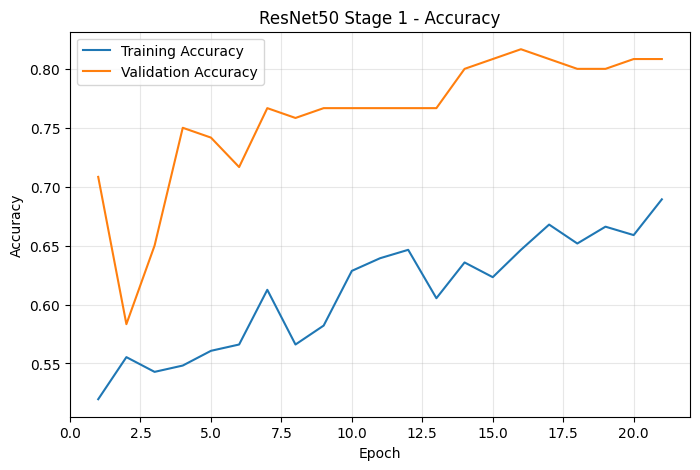

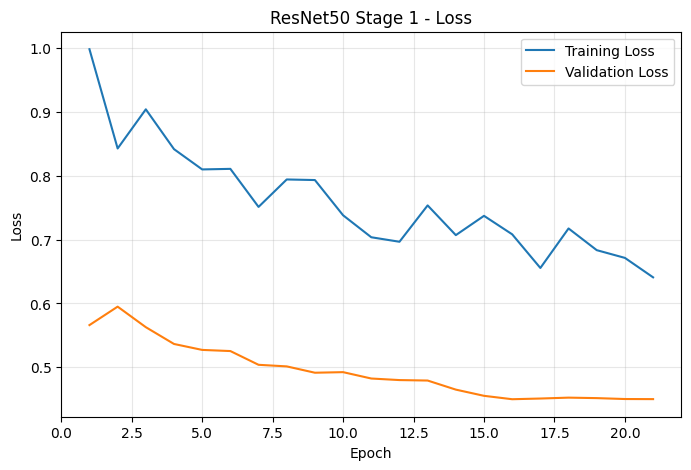

ResNet50 - STAGE 1 ANALYSIS
Epochs completed:             21
Best epoch by val_loss:       16
Best validation loss:         0.4501
Validation accuracy at best:  0.8167

Highest validation accuracy:  0.8167
Highest val accuaracy epoch:  16

Final training accuracy:      0.6893
Final validation accuracy:    0.8083
Final training loss:          0.6409
Final validation loss:        0.4502

Early stopping activated:     YES
Test set used:                  NO
STAGE 1 ANALYSIS COMPLETE


In [ ]:
#ResNet50: stage 1 training analysis
#function to make plotting graphs easier
def plot_curves(x, train_vals, val_vals, ylabel, title, boundary = None):
  plt.figure(figsize = (8, 5))
  plt.plot(x, train_vals, label = f"Training {ylabel}")
  plt.plot(x, val_vals, label=f"Validation {ylabel}")
  if boundary is not None:
    plt.axvline(
        boundary + 0.5, linestyle = "--", color = "grey",
        label = "stage 1 -> stage 2"
    )
  plt.xlabel("Epoch")
  plt.ylabel(ylabel)
  plt.title(title)
  plt.legend()
  plt.grid(alpha = 0.3)
  plt.show()

# extract stage 1 history
stage1_epochs = range(
    1,
    len(history_stage1.history["loss"]) + 1
)

train_accuracy = history_stage1.history["accuracy"]
val_accuracy = history_stage1.history["val_accuracy"]
train_loss = history_stage1.history["loss"]
val_loss = history_stage1.history["val_loss"]

#best epoch
best_epoch = int(np.argmin(val_loss)+1)
best_val_loss = float(np.min(val_loss))
best_val_accuracy = float(val_accuracy[best_epoch-1])
highest_val_accuracy = float(np.max(val_accuracy))
highest_val_accuracy_epoch = int(np.argmax(val_accuracy)+1)

#computing early-stopping status instead of assuming it
s1_epoch_completed = len(train_loss)
s1_early_stopped = s1_epoch_completed < MAX_INITIAL_EPOCHS
s1_still_improving = (best_epoch == s1_epoch_completed)

#plotting curves
plot_curves(stage1_epochs, train_accuracy, val_accuracy,
            "Accuracy", "ResNet50 Stage 1 - Accuracy" )

plot_curves(stage1_epochs, train_loss, val_loss,
            "Loss", "ResNet50 Stage 1 - Loss" )

#Analysis summary
print("=" * 65)
print("ResNet50 - STAGE 1 ANALYSIS")
print("=" * 65)

print(f"Epochs completed:             {s1_epoch_completed}")
print(f"Best epoch by val_loss:       {best_epoch}")
print(f"Best validation loss:         {best_val_loss:.4f}")
print(f"Validation accuracy at best:  {best_val_accuracy:.4f}")

print()
print(f"Highest validation accuracy:  {highest_val_accuracy:.4f}")
print(f"Highest val accuaracy epoch:  {highest_val_accuracy_epoch}")

print()
print(f"Final training accuracy:      {train_accuracy[-1]:.4f}")
print(f"Final validation accuracy:    {val_accuracy[-1]:.4f}")
print(f"Final training loss:          {train_loss[-1]:.4f}")
print(f"Final validation loss:        {val_loss[-1]:.4f}")

print()
print(f"Early stopping activated:     {'YES' if s1_early_stopped else 'NO'}")
if not s1_early_stopped:
  print(f"Reason:                     {MAX_INITIAL_EPOCHS}-epoch lim reached")
  print(
      "Validation loss at last epoch: "
      f"{'STILL IMPROVING' if s1_still_improving else 'NOT IMPROVING'}"
  )
print("Test set used:                  NO")
print("=" * 65)
print("STAGE 1 ANALYSIS COMPLETE")

In [ ]:
#ResNet50: Stage 2 fine-tuning config

#ensuring that stage 2 starts from best stage 1 model weights
model.load_weights(
    STAGE1_CHECKPOINT
)

#enable backbone fine-tuning
resnet50_base.trainable = True

#Freezing everything except last residual stage
#BatchNormalization layers are always kept frozen
for layer in resnet50_base.layers:
  is_conv5 = layer.name.startswith("conv5_block")
  is_batchnorm = isinstance(layer, layers.BatchNormalization)

  if is_conv5 and not is_batchnorm:
    layer.trainable = True
  else:
    layer.trainable = False

#collecting the config
trainable_backbone_layers = [
    layer.name
    for layer in resnet50_base.layers
    if layer.trainable and len(layer.trainable_weights) > 0
]

frozen_backbone_layers = [
    layer.name
    for layer in resnet50_base.layers
    if not layer.trainable
]

bn_layers_frozen = all(
    not layer.trainable
    for layer in resnet50_base.layers
    if isinstance(layer, layers.BatchNormalization)
)

trainable_params = sum (
    np.prod(variable.shape)
    for variable in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.non_trainable_weights
)

#stored for final results export
STAGE2_TRAINABLE_PARAMS = int(trainable_params)
STAGE2_NON_TRAINABLE_PARAMS = int(non_trainable_params)
STAGE2_UNFROZEN_LAYERS = list(trainable_backbone_layers)

#Displaying config
print("=" * 65)
print("ResNet50: STAGE 2 FINE-TUNING CONFIG")
print("=" * 65)

print("Stage 1 checkpoint:       LOADED")
print("ResNet5- backboneL        PARTIALLY UNFROZEN")

print()
print("Frozen sections:           conv1, conv2_x, conv3_x, conv4_x")
print("Trainable section:         conv5_x")
print(f"BatchNorm layers frozen:  {bn_layers_frozen}")

print()
print(f"Unfrozen backbone layers:  {len(trainable_backbone_layers)}")
print(f"Frozen backbone layers:    {len(frozen_backbone_layers)}")
print("First / last unfrozen:       "
        f"{trainable_backbone_layers[0]} / {trainable_backbone_layers[-1]}"
)
print()
print(f"Trainable Parameters:      {trainable_params}")
print(f"Non-trainable parameters:  {non_trainable_params}")

#safety checks
if not trainable_backbone_layers:
  raise RuntimeError(
      "No ResNet50 backbone layers were unfrozen."
  )

if any(
    not name.startswith("conv5_block")
    for name in trainable_backbone_layers
):
    raise RuntimeError(
        "Unexpected ResNet50 layers were unfrozen."
    )

if not bn_layers_frozen:
  raise RuntimeError(
      "BatchNormalization layers must stay frozen during fine-tuning"
  )

print()
print("Fine-tuning LR:         1e-5")
print("Max Stage 2 epochs:     15")
print("Test set:               STILL LOCKED")

print("=" * 65)
print("ResNet50 STAGE 2 CONFIG VERIFIED")

ResNet50: STAGE 2 FINE-TUNING CONFIG
Stage 1 checkpoint:       LOADED
ResNet5- backboneL        PARTIALLY UNFROZEN

Frozen sections:           conv1, conv2_x, conv3_x, conv4_x
Trainable section:         conv5_x
BatchNorm layers frozen:  True

Unfrozen backbone layers:  10
Frozen backbone layers:    153
First / last unfrozen:       conv5_block1_1_conv / conv5_block3_3_conv

Trainable Parameters:      14955521
Non-trainable parameters:  8634240

Fine-tuning LR:         1e-5
Max Stage 2 epochs:     15
Test set:               STILL LOCKED
ResNet50 STAGE 2 CONFIG VERIFIED


In [ ]:
#ResNet50: Stage 2 compilation and call backs
FINE_TUNE_LEARNING_RATE = 1e-5
MAX_FINE_TUNE_EPOCHS = 15

#recompiling for fine-tuning
model.compile(
    optimizer = keras.optimizers.Adam(
        learning_rate = FINE_TUNE_LEARNING_RATE
    ),
    loss = keras.losses.BinaryCrossentropy(),
    metrics = [
        keras.metrics.BinaryAccuracy(
            name = "accuracy"
        )
    ]
)

#stage 2 checkpoint
STAGE2_CHECKPOINT = (
    RESNET50_CHECKPOINT_DIR/
    "ResNet50_stage2_best.keras"
)

#stage 2 callbacks
stage2_callbacks = [
    EarlyStopping(
        monitor = "val_loss",
        patience = EARLY_STOPPING_PATIENCE,
        restore_best_weights = True,
        verbose = 1
    ),
    ModelCheckpoint(
        filepath = str(STAGE2_CHECKPOINT),
        monitor = "val_loss",
        save_best_only = True,
        verbose = 1
    ),
    ReduceLROnPlateau(
        monitor = "val_loss",
        factor = LR_REDUCTION_FACTOR,
        patience = LR_REDUCTION_PATIENCE,
        min_lr = MIN_LEARNING_RATE,
        verbose = 1
    )
]

#Verification
current_lr = float(
    tf.keras.backend.get_value(
        model.optimizer.learning_rate
    )
)

print("=" * 65)
print("ResNet50: STAGE 2 PRE-TRAINING CHECK")
print("=" * 65)

print("Starting point:            Best Stage 1 checkpoint")
print("Trainable ResNet50 part:   conv5_block1 - conv5_block3 (no BatchNorm)")
print("Frozen ResNet50 parts:     conv1 - conv4_x, all BatchNorm layers")

print()
print("Optimizer:                 Adam")
print(f"Learning Rate:             {current_lr:.7f}")
print("Loss:                      Binary Cross-Entropy")
print("Metric:                    Binary Accuracy")

print()
print(f"Maximum epochs:            {MAX_FINE_TUNE_EPOCHS}")
print(f"Early stopping patience:   {EARLY_STOPPING_PATIENCE}")
print(f"LR reduction patience:     {LR_REDUCTION_PATIENCE}")
print("Checkpoint monitor:       val_loss")

print()
print("Stage 2 checkpoint:")
print(STAGE2_CHECKPOINT)

print()
print("Test set:                 LOCKED / NOT LOADED")
print("= * 65")
print("Resnet50 READY FOR STAGE 2 FINE-TUNING")

ResNet50: STAGE 2 PRE-TRAINING CHECK
Starting point:            Best Stage 1 checkpoint
Trainable ResNet50 part:   conv5_block1 - conv5_block3 (no BatchNorm)
Frozen ResNet50 parts:     conv1 - conv4_x, all BatchNorm layers

Optimizer:                 Adam
Learning Rate:             0.0000100
Loss:                      Binary Cross-Entropy
Metric:                    Binary Accuracy

Maximum epochs:            15
Early stopping patience:   5
LR reduction patience:     2
Checkpoint monitor:       val_loss

Stage 2 checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage2_best.keras

Test set:                 LOCKED / NOT LOADED
= * 65
Resnet50 READY FOR STAGE 2 FINE-TUNING


In [ ]:
#ResNet50: Stage 2 fine-tuning

print("=" * 65)
print("ResNet50 - STARTING STAGE 2 FINE-TUNING")
print("=" * 65)

print("Starting point:     Best Stage 1 checkpoint")
print("Trainable block:    conv5_x (BatchNorm frozen)")
print(f"Learning rate:      {FINE_TUNE_LEARNING_RATE}")
print(f"Maximum epochs:     {MAX_FINE_TUNE_EPOCHS}")
print("Test set:           NOT USED")
print("=" * 65)

#record start time
s2_start_time = time.perf_counter()

#fine-tune model
history_stage2 = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = MAX_FINE_TUNE_EPOCHS,
    callbacks = stage2_callbacks,
    verbose = 1
)

#recording end time and calculating duration
s2_end_time = time.perf_counter()
s2_exec_time = (s2_end_time - s2_start_time)/60

#extract results
s2_epochs_completed = len(
    history_stage2.history["loss"]
)

s2_best_epoch = int(
    np.argmin(history_stage2.history["val_loss"]) + 1
)

s2_best_val_loss = float(
    np.min(history_stage2.history["val_loss"])
)

s2_val_accuracy_at_best = float(
    history_stage2.history["val_accuracy"][s2_best_epoch -1]
)

s2_highest_val_accuracy = float(
    np.max(history_stage2.history["val_accuracy"])
)

s2_highest_accuracy_epoch = int(
    np.argmax(history_stage2.history["val_accuracy"]) + 1
)

#summary
print("\n" + "=" * 65)
print("ResNet50 - STAGE 2 FINE-TUNING COMPLETE")
print("=" * 65)

print(f"Epochs completed:                  {s2_epochs_completed}")
print(f"Best epoch by val_loss:            {s2_best_epoch}")
print(f"Best validation loss:              {s2_best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: {s2_val_accuracy_at_best:.4f}")
print(f"Highest accuracy epoch:            {s2_highest_accuracy_epoch}")
print(f"Training duration:                 {s2_exec_time:.2f} minutes")

print()
print("Best  Stage 2 checkpoint:")
print(STAGE2_CHECKPOINT)
print()
print("Test set used:                       No")
print("=" * 65)



ResNet50 - STARTING STAGE 2 FINE-TUNING
Starting point:     Best Stage 1 checkpoint
Trainable block:    conv5_x (BatchNorm frozen)
Learning rate:      1e-05
Maximum epochs:     15
Test set:           NOT USED
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6229 - loss: 0.7152
Epoch 1: val_loss improved from None to 0.46848, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage2_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 100s 5s/step - accuracy: 0.6536 - loss: 0.6598 - val_accuracy: 0.7667 - val_loss: 0.4685 - learning_rate: 1.0000e-05
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7406 - loss: 0.5265
Epoch 2: val_loss improved from 0.46848 to 0.38924, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50/ResNet50_stage2_best.keras



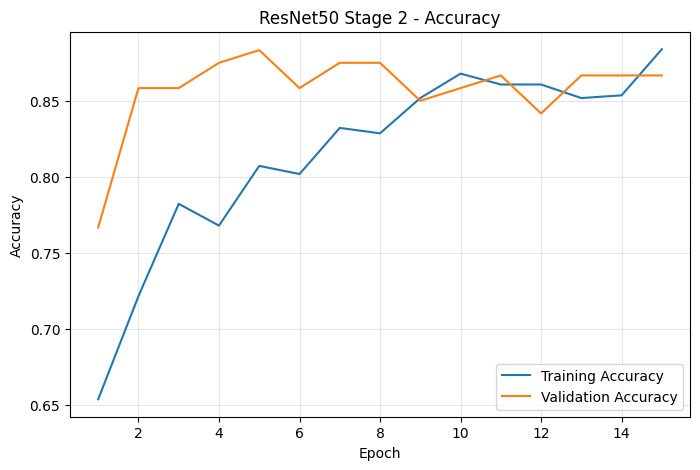

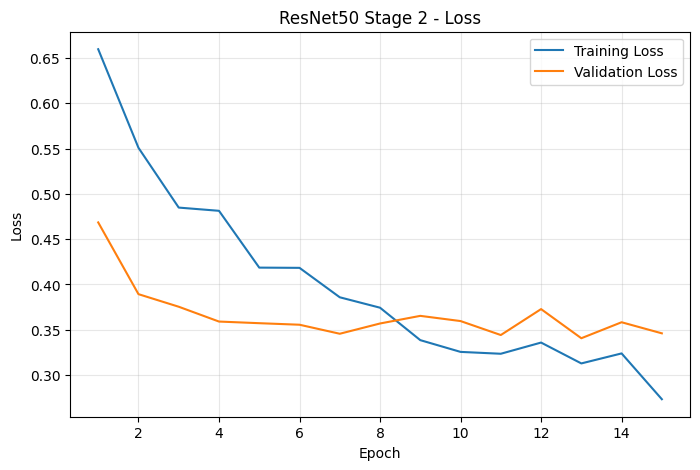

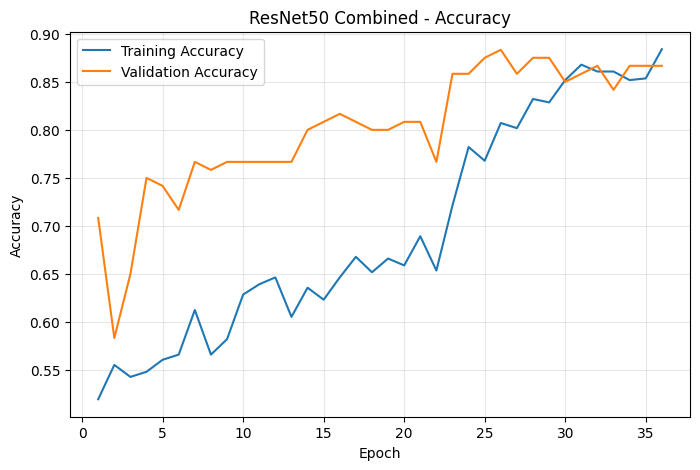

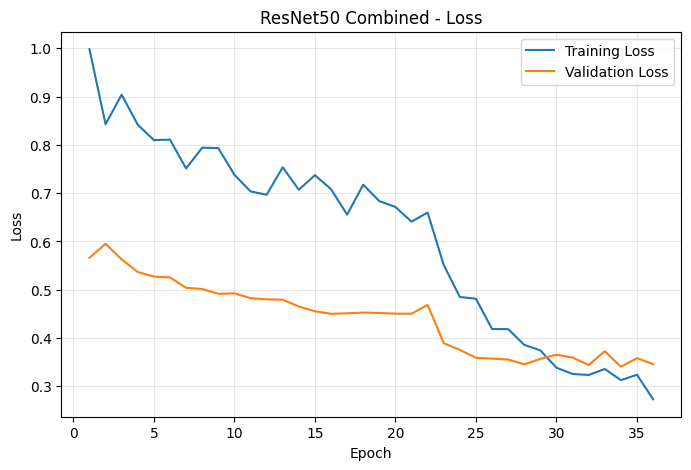

ResNet50 - STAGE 2 ANALYSIS
Epochs completed:             15
Best epoch by val_loss:       13
Best validation loss:         0.3406
Validation accuracy at best:  0.8667

Final training accuracy:      0.8839
Final validation accuracy:    0.8667
Final training loss:          0.2732
Final validation loss:        0.3460

Early stopping activated:     NO

Stage 1 best val_loss:            0.4501(val acc 0.8167)
Stage 2 best val_loss:            0.3406(val acc 0.8667)
Test set used:                  NO
STAGE 2 ANALYSIS COMPLETE


In [ ]:
#ResNet 50: Stage 2 analysis
s2_epochs = range(
    1,
    s2_epochs_completed + 1
)

s2_train_acc = history_stage2.history["accuracy"]
s2_val_acc = history_stage2.history["val_accuracy"]
s2_train_loss = history_stage2.history["loss"]
s2_val_loss = history_stage2.history["val_loss"]

s2_early_stopped = s2_epochs_completed <MAX_FINE_TUNE_EPOCHS

#plotting Stage 2 curves
plot_curves(
    s2_epochs, s2_train_acc, s2_val_acc,
    "Accuracy", "ResNet50 Stage 2 - Accuracy"
)

plot_curves(
    s2_epochs, s2_train_loss, s2_val_loss,
    "Loss", "ResNet50 Stage 2 - Loss"
)
#combined curves - stage 1 and 2
combined_epochs = range(
    1,
    s1_epoch_completed +s2_epochs_completed +1
)
combined_train_acc = train_accuracy + s2_train_acc
combined_val_acc = val_accuracy + s2_val_acc
combined_train_loss = train_loss + s2_train_loss
combined_val_loss = val_loss + s2_val_loss

plot_curves(
    combined_epochs, combined_train_acc, combined_val_acc,
    "Accuracy", "ResNet50 Combined - Accuracy"
)

plot_curves(
    combined_epochs, combined_train_loss, combined_val_loss,
    "Loss", "ResNet50 Combined - Loss"
)

#Summary
print("=" * 65)
print("ResNet50 - STAGE 2 ANALYSIS")
print("=" * 65)

print(f"Epochs completed:             {s2_epochs_completed}")
print(f"Best epoch by val_loss:       {s2_best_epoch}")
print(f"Best validation loss:         {s2_best_val_loss:.4f}")
print(f"Validation accuracy at best:  {s2_val_accuracy_at_best:.4f}")

print()
print(f"Final training accuracy:      {s2_train_acc[-1]:.4f}")
print(f"Final validation accuracy:    {s2_val_acc[-1]:.4f}")
print(f"Final training loss:          {s2_train_loss[-1]:.4f}")
print(f"Final validation loss:        {s2_val_loss[-1]:.4f}")

print()
print(f"Early stopping activated:     {'YES' if s2_early_stopped else 'NO'}")

print()
print("Stage 1 best val_loss:            "
      f"{best_val_loss:.4f}(val acc {best_val_accuracy:.4f})")
print("Stage 2 best val_loss:            "
      f"{s2_best_val_loss:.4f}(val acc {s2_val_accuracy_at_best:.4f})")

print("Test set used:                  NO")
print("=" * 65)
print("STAGE 2 ANALYSIS COMPLETE")
